# Challenge 2: Make the Quantum Coin Biased

**Goal:** Use one qubit and no more than four gates before measurement to produce unequal probabilities.

We use an `RY(θ)` rotation. For a qubit initially in \(|0\rangle\), the probability of measuring `1` is \(\sin^2(θ/2)\). With \(θ=π/3\), the ideal probabilities are 25% `1` and 75% `0`.

In [1]:
# If needed, install Qiskit and Matplotlib by running this in a notebook cell:
# %pip install qiskit qiskit-aer matplotlib

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
SHOTS = 100
print("Qiskit setup ready. Shots per experiment:", SHOTS)

Qiskit setup ready. Shots per experiment: 100


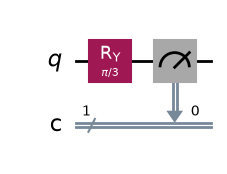

Measured counts: {'0': 66, '1': 34}
Ideal P(0) = 0.75
Ideal P(1) = 0.25


In [2]:
import numpy as np

theta = np.pi / 3
qc = QuantumCircuit(1, 1)
qc.ry(theta, 0)
qc.measure(0, 0)

display(qc.draw("mpl"))
result = simulator.run(transpile(qc, simulator), shots=SHOTS).result()
counts = result.get_counts()
print("Measured counts:", counts)
print("Ideal P(0) =", round(np.cos(theta / 2) ** 2, 3))
print("Ideal P(1) =", round(np.sin(theta / 2) ** 2, 3))
plot_histogram(counts)
plt.show()

## Bonus: Bias toward `1`

Change the angle to \(θ=2π/3\). This gives ideal probabilities of 25% `0` and 75% `1`.

In [3]:
theta_bonus = 2 * np.pi / 3
qc_bonus = QuantumCircuit(1, 1)
qc_bonus.ry(theta_bonus, 0)
qc_bonus.measure(0, 0)

result_bonus = simulator.run(transpile(qc_bonus, simulator), shots=SHOTS).result()
counts_bonus = result_bonus.get_counts()
print("Bonus counts:", counts_bonus)
plot_histogram(counts_bonus)
plt.show()

Bonus counts: {'1': 79, '0': 21}


## Challenge question: How can quantum gates change measurement probabilities?

Quantum gates change the qubit's state and its probability amplitudes. Measurement probabilities are the squared magnitudes of those amplitudes. A rotation such as `RY(θ)` controls the balance between outcomes `0` and `1`. With 100 shots, observed counts are approximate and may not exactly match the ideal percentages.